In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import jax.random as jrandom
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import MinMaxScaler
from dataclasses import dataclass
import jax
import jax.numpy as jnp
import flax.nnx as nnx
from functools import partial
from diffrax import ODETerm, Euler, Dopri5, AbstractSolver
import jax_dataloader as jdl
from tqdm import tqdm
import diffrax as dfx 
from dyn_plot import Plot 
import optax
from functools import partial


## 1. Load dataset

In [2]:
import scipy.io
import os
import re
import numpy as np

def load_and_downsample_data(dir_path, seizure=False, downsample_factor=4, n_channels=16):
    """
    Loads and downsamples EEG data from .mat files in a directory.

    Args:
        dir_path (str): Path to the directory containing the .mat files.
        seizure (bool): If True, load seizure data. If False, load interictal data.
        downsample_factor (int): Factor by which to downsample the data.
        n_channels (int): Number of EEG channels to load.

    Returns:
        - data (np.ndarray): Array of shape (num_segments, time, n_channels)
        - freqs (np.ndarray): Array of shape (num_segments, 1) containing the frequency of each segment.
    """
    prefix = "Patient_1_ictal" if seizure else "Patient_1_interictal"
    pattern = r"{}_segment_(\d+)\.mat$".format(prefix)  # Capture segment number

    mat_files = []
    for root, _, files in os.walk(dir_path):
        for file in files:
            match = re.match(pattern, file)
            if match:
                mat_files.append(os.path.join(root, file))

    print(f"Found {len(mat_files)} matching files.")
    if not mat_files:
        return np.array([])

    all_data = []
    for file_path in mat_files:
        try:
            data = scipy.io.loadmat(file_path)
            channels_names = data["channels"]
            channels_data = data["data"]
            downsampled_data = channels_data[:n_channels, ::downsample_factor]
            all_data.append(downsampled_data.T)

        except Exception as e:
            print(f"Error processing file {file_path}: {e}. Skipping.")
            continue

    if not all_data: # Check if all_data is empty *after* processing
       return np.array([])

    return channels_names, np.stack(all_data, axis=0)

dir_path = "/Users/ahmed.elgazzar/Desktop/Datasets/EEG/Kaggle_eeg_seizure/Patient_1/" # Replace with your path
seizure = True
downsample_factor = 4
n_channels = 4  
batch_size = 32

# Load interictal data
channels, data = load_and_downsample_data(dir_path, seizure=seizure, downsample_factor=downsample_factor, n_channels=n_channels)
#scale data
scaler = MinMaxScaler()
data = scaler.fit_transform(data.reshape(-1, n_channels)).reshape(data.shape)
dataloader = jdl.DataLoader(jdl.ArrayDataset(data), 'jax', batch_size=batch_size, shuffle=True)
print(f"data shape: {data.shape if data.size > 0 else 'No data loaded'}")



Found 70 matching files.
data shape: (70, 125, 4)


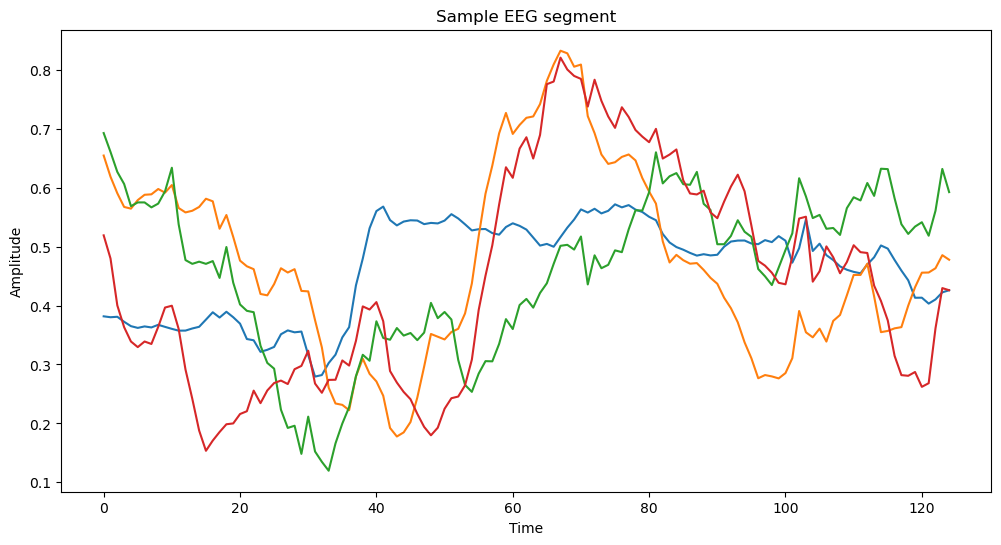

In [3]:
# Plot a sample segment
sample_segment = 13
plt.figure(figsize=(12, 6))
ax = plt.plot(data[sample_segment])
plt.title("Sample EEG segment")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.show()


## Model Setup

In [4]:
@dataclass
class SinusodialPosEmb(nnx.Module):
    dim: int
    length: int

    def __call__(self, t):
        freqs = jnp.arange(1, self.dim//2 + 1) * jnp.pi
        emb = t[:, None] * freqs[None, :]
        emb = jnp.concatenate([jnp.sin(emb), jnp.cos(emb)], axis=-1) 
        return jnp.repeat(emb, self.length, axis=0)

def generate_noise(key, N, T, scale=1.0):
    """
    Generates N Brownian motion time series of length T
    scale: scale of the Brownian motion
    """
    key_noise = jrandom.split(key, N)
    
    def single_brownian(noise_key):
        noise = jrandom.normal(noise_key, (T,))
        series = jnp.cumsum(noise, axis=0)
        return series
    
    series = jax.vmap(single_brownian)(key_noise)
    return series 


# %TODO: implement using diffrax and flax.nnx
class CoupledOscillators(nnx.Module):
    def __init__(self, n_oscillators, solver):
        super().__init__()
        self.sigma = nnx.Param(n_oscillators)
        self.omega = nnx.Param(n_oscillators)
        self.K = nnx.Param()
        self.vector_field = ODETerm()
        self.solver = solver

    def __call__(self, x, t):
        # solve and return the solution of the ODE
        return


# %TODO: Replace RNN with Coupled Oscillators
class TimeRNNBlock(nnx.Module):
    def __init__(self, dim_in: int, dim_out: int, time_dim: int, length_dim: int, rngs: nnx.Rngs):
        self.dim_in = dim_in
        self.dim_out = dim_out
        self.time_dim = time_dim
        self.time_emb = SinusodialPosEmb(time_dim, length_dim)
        self.lstm_fwd = nnx.nn.recurrent.OptimizedLSTMCell(dim_in +  time_dim, dim_out, rngs=rngs)
        self.lstm_bwd = nnx.nn.recurrent.OptimizedLSTMCell(dim_in +  time_dim, dim_out, rngs=rngs)


    def __call__(self, x, t):
        time_emb = self.time_emb(t)  
        x_combined = jnp.concatenate([x, time_emb], axis=-1)
        def scan_fn(carry, x_t):
            carry_fw, carry_bw = carry
            carry_fw, out_fw = self.lstm_fwd(carry_fw, x_t)
            carry_bw, out_bw = self.lstm_bwd(carry_bw, x_t[::-1]) 
            return (carry_fw, carry_bw), (out_fw, out_bw)

        hidden_dim = self.lstm_fwd.hidden_features  
        initial_carry = ((jnp.zeros((hidden_dim,), x.dtype), jnp.zeros((hidden_dim,), x.dtype)),(jnp.zeros((hidden_dim,), x.dtype), jnp.zeros((hidden_dim,), x.dtype)))
        _, (outputs_fw, outputs_bw) = jax.lax.scan(scan_fn, initial_carry, x_combined)
        outputs = jnp.concatenate([outputs_fw, outputs_bw[::-1]], axis=-1) 
        return outputs
    
class Flow(nnx.Module):
    def __init__(self, dim_in: int, dim_hidden:int, time_dim:int, length_dim:int, n_hidden_blocks:int, rngs: nnx.Rngs):
        self.dim_in, self.dim_hidden = dim_in, dim_hidden
        self.time_dim, self.length_dim = time_dim, length_dim
        self.input_layer = nnx.Conv(dim_in, dim_hidden, kernel_size=1, rngs=rngs)
        self.hidden_blocks = [TimeRNNBlock(dim_hidden, dim_hidden//2, time_dim, length_dim, rngs=rngs) for _ in range(n_hidden_blocks)] 
        self.output_layer = nnx.Conv(dim_hidden, dim_in, kernel_size=1, rngs=rngs)

    @nnx.jit
    def __call__(self, x, t):
        x = self.input_layer(x)
        for block in self.hidden_blocks:
            x = block(x, t)
        x = self.output_layer(x)
        return x
    

rngs = nnx.Rngs(0)
x_batch = next(iter(dataloader))[0]

flow_model = Flow(dim_in=x_batch.shape[2], dim_hidden=64, time_dim=4, length_dim=x_batch.shape[1], n_hidden_blocks=1, rngs=rngs)



# test forward pass
pred = flow_model(x_batch[0], jnp.array([0.0]))
print(pred.shape)


(125, 4)


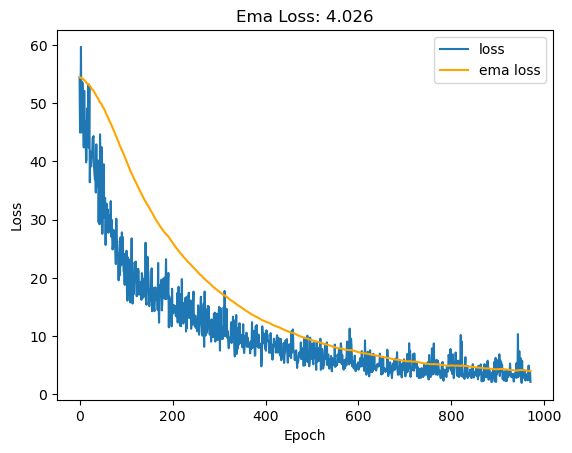

100%|██████████| 1000/1000 [00:52<00:00, 18.94it/s]


In [5]:
def loss_fn(flow_model, x1, rngs):
    
    t = jrandom.uniform(rngs(), (x1.shape[0],), minval=0.0, maxval=1.0)
    
    # Generate x0 samples
    x0_keys = jrandom.split(rngs(), x1.shape[0])
    x0 = jax.vmap(generate_noise, in_axes=(0, None, None))(x0_keys, x1.shape[2], x1.shape[1])
    x0 = jnp.transpose(x0, (0, 2, 1))
    
    # Compute x_t using  linear interpolation
    x_t = (1 - t[:, None, None]) * x0 + t[:, None, None] * x1
    
    # Compute flows
    pred_flow = jax.vmap(flow_model, in_axes=(0, 0))(x_t, t[:,None])
    optimal_flow = x1 - x0
    
    # Compute loss
    loss = jnp.mean(jnp.square(pred_flow - optimal_flow))
    
    return loss

@nnx.jit
def train_step(model, optimizer, x, rngs):
    loss, grads = nnx.value_and_grad(loss_fn)(model, x, rngs)
    optimizer.update(grads)
    return loss

# Initialize optimizer and RNG
rng_key = jrandom.PRNGKey(0)
optimizer = nnx.Optimizer(flow_model, optax.adam(1e-3))

loss_plot = Plot()
losses = []
ema_losses = []
ema_loss = None
rngs = nnx.Rngs(0)

for epoch in tqdm(range(1000)):
    epoch_loss = 0.0
    for batch_idx, (x,) in enumerate(dataloader):
        loss = train_step(flow_model, optimizer, x, rngs)
        epoch_loss += loss
    
    avg_epoch_loss = epoch_loss / (batch_idx + 1)
    losses.append(float(avg_epoch_loss))
    
    # Update EMA loss
    if epoch >= 10:
        ema_loss = avg_epoch_loss if ema_loss is None else 0.99 * ema_loss + 0.01 * avg_epoch_loss
        ema_losses.append(float(ema_loss))
    
    # Plotting every 20 epochs
    if epoch % 20 == 0:
        with loss_plot:
            loss_plot.clear()
            loss_plot.plot(losses[10:], label='loss')
            loss_plot.plot(ema_losses, label='ema loss', color='orange')
            if ema_loss is not None:
                loss_plot.set_title(f"Ema Loss: {ema_loss:.3f}")
            loss_plot.set_xlabel("Epoch")
            loss_plot.set_ylabel("Loss")
            loss_plot.legend()

loss_plot.close()


# Sampling the trained model

In [9]:
def sample_flow(model, key, n_channels, n_timepoints, n_steps_flow=100, n_samples=100):
    
    def predict(key, n_steps_flow, n_timepoints, n_channels):
        def vf(t, x, args):
            return model(x, jnp.array([t]))
            
        term = ODETerm(vf)
        solver = dfx.Euler()
        dt = 1/n_steps_flow
        x0 = generate_noise(key, n_channels, n_timepoints)
        x0 = jnp.transpose(x0, (1, 0))
        predictions = dfx.diffeqsolve(term, solver, 0., 1., dt, x0, saveat=dfx.SaveAt(t1=True)).ys
        return predictions

    key_samples = jrandom.split(key, n_samples)
    
    # First vmap over batch, then over samples
    vmapped_predict = jax.vmap(predict, in_axes=(0, None, None, None)) 
    
    samples = vmapped_predict(key_samples, n_steps_flow, n_timepoints, n_channels)
    return jnp.squeeze(samples, axis=1)



In [10]:
# Sample from the flow
sample = sample_flow(flow_model, jrandom.PRNGKey(0), n_channels, x_batch.shape[1], 100, 10)
print(sample.shape)


(10, 125, 4)


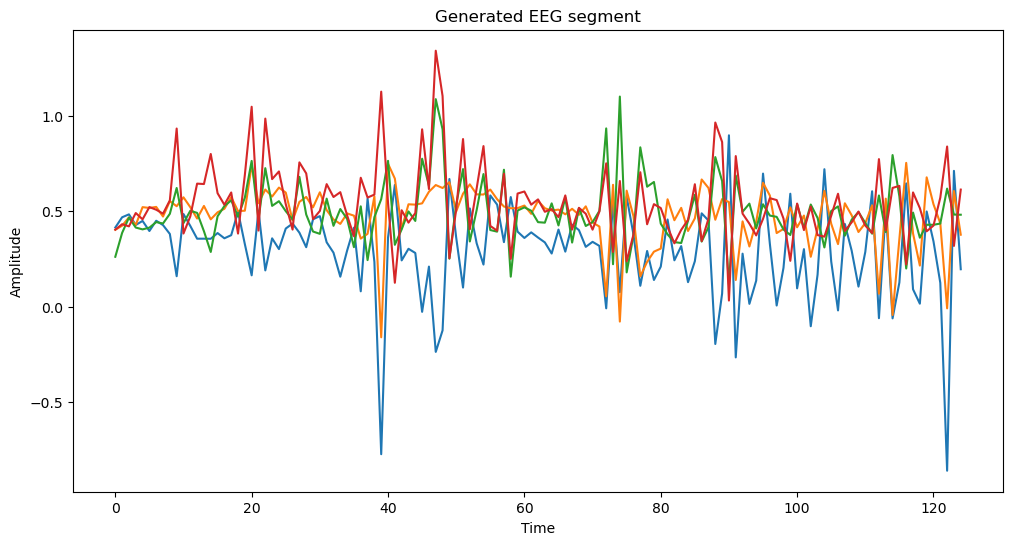

In [15]:
plt.figure(figsize=(12, 6))
plt.plot(sample[1,:, :])
plt.title("Generated EEG segment")
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.show()